# Kelly Monte Carlo Lab

This notebook is a didactic, step-by-step version of the core Monte Carlo
simulations used in the codebase. It focuses on a single fixed-fraction
strategy defined in terms of R-multiples per trade.

The main goals are to:

- Define the trading strategy configuration (edge, R-multiples, risk per trade)
- Generate many independent equity paths via Monte Carlo simulation
- Measure risk-of-ruin, maximum drawdown, and distribution of final equity
- Build intuition for how small changes in edge or risk fraction affect
  the entire distribution of outcomes

Use this notebook to experiment interactively with parameters before moving
on to the more advanced Kelly and regime-based scripts in `src/`.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:

# CONFIGURATION: We will apply the characteristics of the trading strategy. 
#This will be the basis of how our equity paths are formed throughout the simulations

STARTING_CAPITAL = 10_000.0

YEARS = 2
DAYS_PER_YEAR = 252
TRADES_PER_DAY = 4

SIMULATIONS = 50_000

WIN_RATE = 0.40
R_WIN = 2.0
R_LOSS = 1.0

FIXED_FRACTION = 0.0075
RUIN_FRACTION = 0.50

In [ ]:
# =====================================================
# DERIVED VALUES
# =====================================================

TOTAL_TRADES = YEARS * DAYS_PER_YEAR * TRADES_PER_DAY
RUIN_LEVEL = STARTING_CAPITAL * RUIN_FRACTION


In [ ]:
# =====================================================
# 1) GENERATE RANDOM TRADE OUTCOMES
# =====================================================

# Uniform random matrix
u = np.random.rand(SIMULATIONS, TOTAL_TRADES)

# Convert to win/loss boolean matrix
wins = (u < WIN_RATE)

# Convert to R-multiples
r_matrix = np.where(wins, R_WIN, -R_LOSS)


In [ ]:
# =====================================================
# 2) ESTIMATE EMPIRICAL KELLY FRACTION
# =====================================================

"""
We treat R-multiples as per-trade returns.
Empirical Kelly formula (continuous approximation):

    f* = μ / σ²

Where:
    μ = mean return per trade
    σ² = variance of return per trade
"""

mu = np.mean(r_matrix)
sigma_squared = np.var(r_matrix)

kelly_fraction = mu / sigma_squared

half_kelly = 0.5 * kelly_fraction
full_kelly = kelly_fraction

print("Empirical Kelly Fraction:", kelly_fraction)


Empirical Kelly Fraction: 0.09261517024781148


In [ ]:
# =====================================================
# 3) BUILD RETURN MATRICES FOR EACH SIZING RULE
# =====================================================

"""
Convert R-multiples into growth multipliers:

    return = 1 + (fraction * R)
"""

return_fixed = 1 + (FIXED_FRACTION * r_matrix)
return_half = 1 + (half_kelly * r_matrix)
return_full = 1 + (full_kelly * r_matrix)

In [ ]:
# =====================================================
# 4) EQUITY COMPOUNDING FUNCTION
# =====================================================

def compound_paths(return_matrix):
    """
    Compounds trade multipliers into full equity paths.

    Parameters
    ----------
    return_matrix : np.ndarray
        Matrix of per-trade multipliers
        Shape: (simulations, trades)

    Returns
    -------
    equity_matrix : np.ndarray
        Full equity paths including time 0
        Shape: (simulations, trades + 1)
    """

    compounded = np.cumprod(return_matrix, axis=1)

    equity = STARTING_CAPITAL * compounded

    equity = np.column_stack(
        (np.full(SIMULATIONS, STARTING_CAPITAL), equity)
    )

    return equity


equity_fixed = compound_paths(return_fixed)
equity_half = compound_paths(return_half)
equity_full = compound_paths(return_full)
    

In [ ]:
# =====================================================
# 5) RISK METRIC FUNCTIONS
# =====================================================

def compute_max_drawdown(equity_matrix):
    """
    Computes maximum drawdown for each simulation path.
    """
    running_peak = np.maximum.accumulate(equity_matrix, axis=1)
    drawdowns = (running_peak - equity_matrix) / running_peak
    return np.max(drawdowns, axis=1)


def compute_ruin_probability(equity_matrix):
    """
    Computes probability of hitting ruin threshold.
    """
    min_equity = np.min(equity_matrix, axis=1)
    return np.mean(min_equity < RUIN_LEVEL)

    annualization_factor = np.sqrt(DAYS_PER_YEAR * TRADES_PER_DAY)

    return mean_returns / std_returns * annualization_factor
def compute_sharpe(equity_matrix):
    """
    Computes annualized Sharpe ratio per simulation.
    """
    log_returns = np.log(equity_matrix[:, 1:] / equity_matrix[:, :-1])
    mean_returns = np.mean(log_returns, axis=1)
    std_returns = np.std(log_returns, axis=1)

    annualization_factor = np.sqrt(DAYS_PER_YEAR * TRADES_PER_DAY)

    return mean_returns / std_returns * annualization_factor


In [ ]:
# =====================================================
# 6) COMPUTE METRICS FOR EACH STRATEGY
# =====================================================

final_fixed = equity_fixed[:, -1]
final_half = equity_half[:, -1]
final_full = equity_full[:, -1]

max_dd_fixed = compute_max_drawdown(equity_fixed)
max_dd_half = compute_max_drawdown(equity_half)
max_dd_full = compute_max_drawdown(equity_full)

ruin_fixed = compute_ruin_probability(equity_fixed)
ruin_half = compute_ruin_probability(equity_half)
ruin_full = compute_ruin_probability(equity_full)

sharpe_fixed = compute_sharpe(equity_fixed)
sharpe_half = compute_sharpe(equity_half)
sharpe_full = compute_sharpe(equity_full)

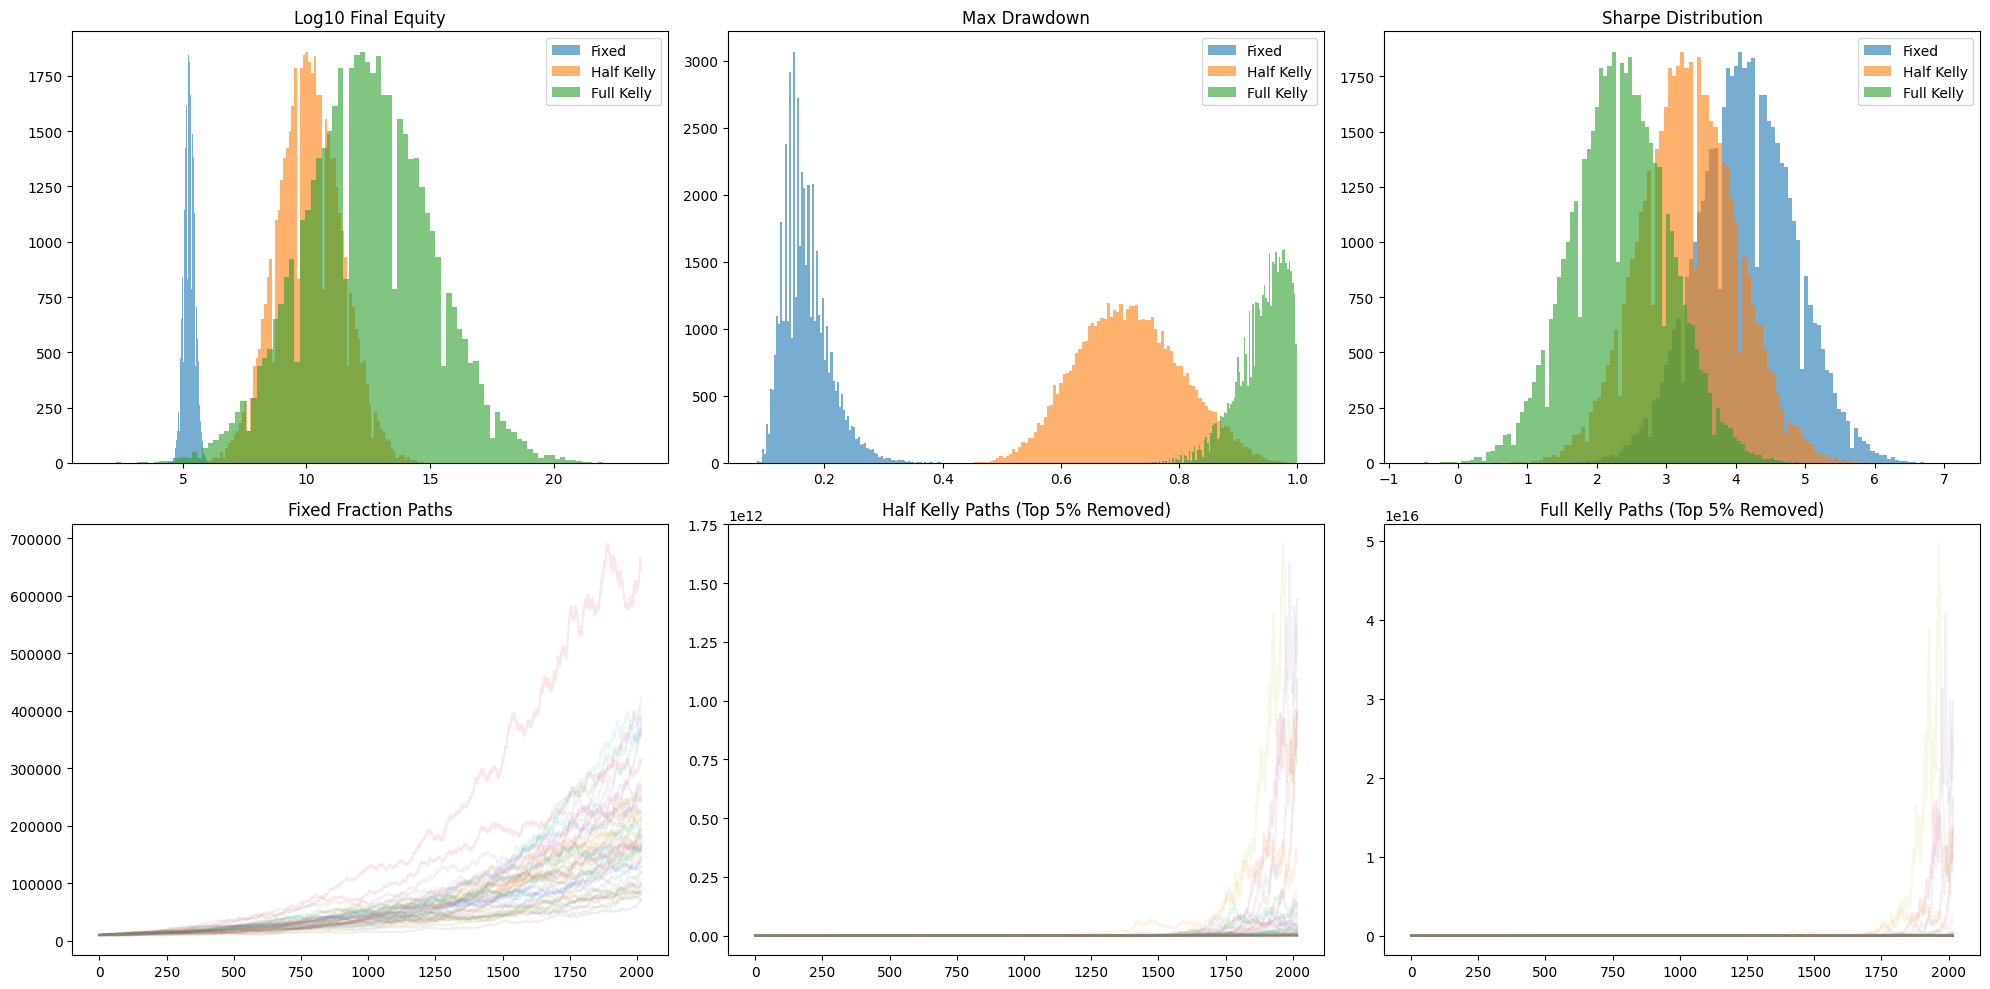

In [ ]:
# =====================================================
# VISUALIZATION — CLEAN PRESENTATION LAYOUT
# =====================================================

plt.figure(figsize=(20, 10))

# -----------------------------------------------------
# ROW 1 — DISTRIBUTIONS
# -----------------------------------------------------

# 1) Log Final Equity
plt.subplot(2, 3, 1)
plt.hist(np.log10(final_fixed), bins=100, alpha=0.6, label="Fixed")
plt.hist(np.log10(final_half), bins=100, alpha=0.6, label="Half Kelly")
plt.hist(np.log10(final_full), bins=100, alpha=0.6, label="Full Kelly")
plt.title("Log10 Final Equity")
plt.legend()


# 2) Max Drawdown
plt.subplot(2, 3, 2)
plt.hist(max_dd_fixed, bins=100, alpha=0.6, label="Fixed")
plt.hist(max_dd_half, bins=100, alpha=0.6, label="Half Kelly")
plt.hist(max_dd_full, bins=100, alpha=0.6, label="Full Kelly")
plt.title("Max Drawdown")
plt.legend()


# 3) Sharpe
plt.subplot(2, 3, 3)
plt.hist(sharpe_fixed, bins=100, alpha=0.6, label="Fixed")
plt.hist(sharpe_half, bins=100, alpha=0.6, label="Half Kelly")
plt.hist(sharpe_full, bins=100, alpha=0.6, label="Full Kelly")
plt.title("Sharpe Distribution")
plt.legend()


# -----------------------------------------------------
# ROW 2 — EQUITY PATHS (TRIMMED TOP 5% FOR VISUALIZATION)
# -----------------------------------------------------

# Determine 95th percentile cutoff for final equity
cut_half = np.percentile(final_half, 95)
cut_full = np.percentile(final_full, 95)

# Indices below cutoff
idx_half = np.where(final_half <= cut_half)[0]
idx_full = np.where(final_full <= cut_full)[0]


# Fixed Paths (unchanged)
plt.subplot(2, 3, 4)
for i in range(50):
    plt.plot(equity_fixed[i], alpha=0.1)
plt.title("Fixed Fraction Paths")


# Half Kelly Paths (trimmed)
plt.subplot(2, 3, 5)
for i in idx_half[:50]:
    plt.plot(equity_half[i], alpha=0.1)
plt.title("Half Kelly Paths (Top 5% Removed)")


# Full Kelly Paths (trimmed)
plt.subplot(2, 3, 6)
for i in idx_full[:50]:
    plt.plot(equity_full[i], alpha=0.1)
plt.title("Full Kelly Paths (Top 5% Removed)")


plt.tight_layout()
plt.show()